In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Séance: 6
Nom :Curticia;
Porteur :P3;
Etapes Assignées : 1.6 ,1.4,1.9,1.12

### 1-6: Les Trous


In [ ]:
import os

print(os.listdir("/kaggle/input"))

In [ ]:
import os

for racine, dossiers, fichiers in os.walk("/kaggle/input"):
    print("Dossier :", racine)
    print("Sous-dossiers :", dossiers)
    print("Fichiers :", fichiers)

In [ ]:
import os

for dossier, sous_dossiers, fichiers in os.walk("/kaggle/input"):
    for fichier in fichiers:
        print(os.path.join(dossier, fichier))

In [1]:
#Trous
import pandas as pd

# 1. Charger les données
train = pd.read_csv("/kaggle/input/datasets/mrdwin/groupe5-allstate-appautomatque-l2-esgcvak/train.csv")
a_estimer = pd.read_csv("/kaggle/input/datasets/mrdwin/groupe5-allstate-appautomatque-l2-esgcvak/a_estimer.csv")

# 2. Compter les valeurs manquantes
trous_train = train.isna().sum()
trous_estimation = a_estimer.isna().sum()

# Pourcentage de valeurs manquantes dans train
taux_train = train.isna().mean() * 100

# Trier du plus rempli au moins rempli
tableau_train = pd.DataFrame({
    "Pourcentage_manquant": taux_train,
    "Pourcentage_rempli": 100 - taux_train
})

tableau_train = tableau_train.sort_values(
    by="Pourcentage_rempli",
    ascending=False
)

print("Résultats pour train :")
display(tableau_train)
taux_estimation = a_estimer.isna().mean() * 100

tableau_estimation = pd.DataFrame({
    "Pourcentage_manquant": taux_estimation,
    "Pourcentage_rempli": 100 - taux_estimation
})

tableau_estimation = tableau_estimation.sort_values(
    by="Pourcentage_rempli",
    ascending=False
)

print("Résultats pour a_estimer :")
display(tableau_estimation)

Résultats pour train :


,Pourcentage_manquant,Pourcentage_rempli
id,0.0,100.0
cat1,0.0,100.0
cat2,0.0,100.0
cat3,0.0,100.0
cat4,0.0,100.0
...,...,...
cont11,0.0,100.0
cont12,0.0,100.0
cont13,0.0,100.0
cont14,0.0,100.0


Résultats pour a_estimer :


,Pourcentage_manquant,Pourcentage_rempli
id,0.0,100.0
cat1,0.0,100.0
cat2,0.0,100.0
cat3,0.0,100.0
cat4,0.0,100.0
...,...,...
cont10,0.0,100.0
cont11,0.0,100.0
cont12,0.0,100.0
cont13,0.0,100.0


In [2]:
#Cardinalité
# Compter les valeurs différentes de toutes les colonnes
cardinalite = train.nunique()

# Créer le tableau
tableau_cardinalite = pd.DataFrame({
    "Cardinalite": cardinalite
})

# Trier du plus grand au plus petit
tableau_cardinalite = tableau_cardinalite.sort_values(
    by="Cardinalite",
    ascending=False
)

# Afficher le résultat
display(tableau_cardinalite)

,Cardinalite
id,150654
loss,130784
cont14,17600
cont7,5439
cont6,2525
...,...
cat68,2
cat71,2
cat69,2
cat70,2


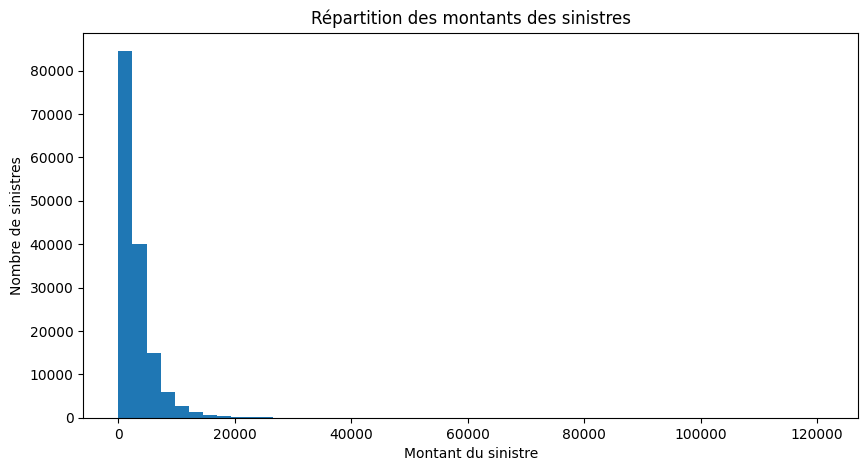

In [22]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(train["loss"], bins=50)

plt.xlabel("Montant du sinistre")
plt.ylabel("Nombre de sinistres")
plt.title("Répartition des montants des sinistres")

plt.show()

In [23]:
#Cibles
from sklearn.model_selection import train_test_split

# Séparer les données : 80 % apprentissage et 20 % test
apprentissage, test = train_test_split(
    train,
    test_size=0.2,
    random_state=0
)

# Afficher la répartition de loss dans l'apprentissage
print("Répartition de loss dans l'apprentissage :")
display(apprentissage["loss"].describe())

# Afficher la répartition de loss dans le test
print("Répartition de loss dans le test :")
display(test["loss"].describe())

# Calculer les deux proportions
taux_apprentissage = len(apprentissage) / len(train) * 100
taux_test = len(test) / len(train) * 100

print("Taux d'apprentissage :", taux_apprentissage, "%")
print("Taux de test :", taux_test, "%")

Répartition de loss dans l'apprentissage :


count    120523.000000
mean       3040.659921
std        2937.537868
min           5.250000
25%        1204.450000
50%        2119.070000
75%        3857.060000
max      121012.250000
Name: loss, dtype: float64

Répartition de loss dans le test :


count    30131.000000
mean      3031.974296
std       2823.134148
min          0.670000
25%       1205.790000
50%       2101.660000
75%       3898.565000
max      43707.250000
Name: loss, dtype: float64

Taux d'apprentissage : 79.99986724547638 %
Taux de test : 20.000132754523612 %


# Le coût des erreurs

Dans notre projet, nous cherchons à prédire le montant des sinistres (`loss`) pour une compagnie d'assurance.

Deux types d'erreurs peuvent se produire :

**1. La sous-estimation :** le modèle prédit un montant inférieur au montant réel. Cela peut entraîner une insuffisance des sommes prévues pour indemniser les assurés.

**2. La surestimation :** le modèle prédit un montant supérieur au montant réel. Cela peut entraîner une prévision excessive des sommes nécessaires et immobiliser inutilement les ressources de l'assureur.

D'après la partie 1.9, les montants des sinistres sont très dispersés : la moyenne est d'environ 3 040 et certains montants dépassent 100 000.

**Conclusion :** les deux erreurs peuvent avoir des conséquences financières importantes. Il est donc nécessaire de choisir une métrique adaptée pour évaluer les prédictions et limiter les erreurs importantes.